Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc, and save it to folder with name $date/

ground truth lat, lon, alt:  40.1171203863895 -88.22639025706695 191.86824283954982
6Mar2024_04_19
Calibrating the phase offsets between the three USRPs...
Calibration done, results saved in 6Mar2024_04_19/info.mat


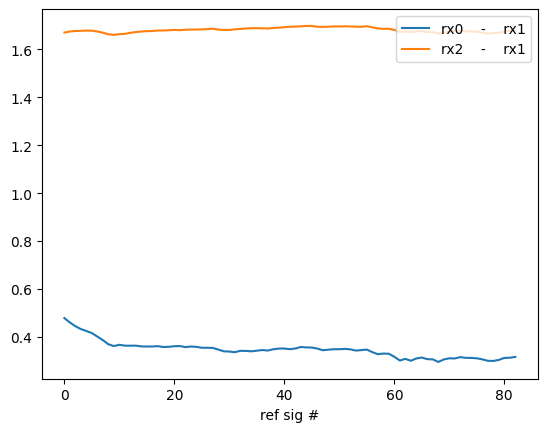

878.730304


In [1]:
from utils.calibration import CalibrationSignal
from utils.imu_data import IMUData
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_12Mar2024_23_17_14_freq_11_325G_bw_2.0M_ts_1710285434.4520473_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_12Mar2024_23_35_44_freq_11_325G_bw_2.0M_ts_1710286544.4498281_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_00_35_58_freq_11_325G_bw_2.0M_ts_1710290158.7682009_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_00_54_22_freq_11_325G_bw_2.0M_ts_1710291262.7842135_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_02_20_20_freq_11_325G_bw_2.0M_ts_1710296420.6706645_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_03_17_04_freq_11_325G_bw_2.0M_ts_1710299824.358615_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_03_59_01_freq_11_325G_bw_2.0M_ts_1710302341.7380192_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_05_37_23_freq_11_325G_bw_2.0M_ts_1710308243.820163_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
iq0_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_33_freq_11_325G_bw_2.0M_ts_1709698773.3134246_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
# iq0_path = 'aa'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_12_23_16_53.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_12_23_35_25.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_00_35_37.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_00_54_03.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_02_20_00.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_03_16_43.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_03_58_41.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_05_37_03.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_04_19_12.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/2_20/imu_utctime_2024_02_20_23_19_38.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/2_5/imu_20240205235759.txt'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
# date = '5Feb2024_23-58-08'
# start_time = 1707177488.0938272
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
d, lam = 13.25e-2, 299792458 / fc
imu = IMUData(imu_path)
imu_data = imu.read_imu_data()
lat, lon, alt = imu.get_latlonalt_()
lat_gt, lon_gt, alt_gt = np.mean(lat), np.mean(lon), np.mean(alt)
orient = imu.get_attitude()
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
print('ground truth lat, lon, alt: ', lat_gt, lon_gt, alt_gt)
print(date)
print('Calibrating the phase offsets between the three USRPs...')
cal0 = CalibrationSignal(iq0_path, fc, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
cal1 = CalibrationSignal(iq1_path, fc, tx_freq, sample_rate)
cal2 = CalibrationSignal(iq2_path, fc, tx_freq, sample_rate)
ref_sig_idx = cal0.get_all_refsigidx() # use the get_all_refsigidx() method to get the start and stop index of the reference signal
phase_0 = cal0.get_refsig_phase(ref_sig_idx)
phase_1 = cal1.get_refsig_phase(ref_sig_idx)
phase_2 = cal2.get_refsig_phase(ref_sig_idx)

t_end = ref_sig_idx[-1][1]/sample_rate  # use the stop time of the last ref sig as the duration of the file
phase_offset_01 = np.unwrap(phase_0-phase_1)
phase_offset_21 = np.unwrap(phase_2-phase_1)

if not os.path.exists(date):
    os.makedirs(date)
# save sample_rate, date, start_time, loc_sig_idx to .mat file
sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idx, 't_end': t_end, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt})
print('Calibration done, results saved in ' + date + '/info.mat')
plt.figure(10)
plt.clf()
plt.plot(phase_offset_01, label='rx0    -    rx1')
plt.plot(phase_offset_21, label='rx2    -    rx1')
plt.xlabel('ref sig #')
plt.legend(loc='upper right')
plt.show()
print(t_end)

Step 2: do the central tone tracking using matlab

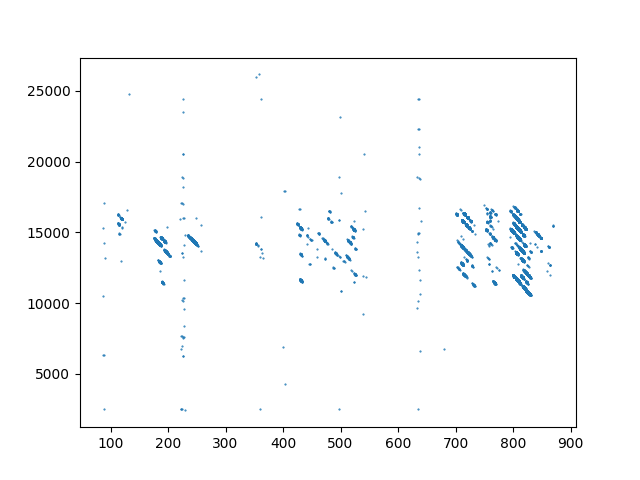

In [2]:
# need to change date first in matlab file
# matlab
# cd Starloc/
# phase_from_bin_track
# results saved to $date/res.mat
# have a look at the results
from matplotlib import pyplot as plt
from scipy import io as sio
%matplotlib widget
res = sio.loadmat(date + '/res.mat')['res']
plt.figure(1)
plt.clf()
plt.plot(res[:, 0].real, res[:, 1].real, '.', markersize=1)
plt.show()

Step 3: simulate doppler, first need to move the tle file to the date folder with name `Starlink.tle`

THIS STEP CAN BE SKIPPED IF USING BLIND ID IDENTIFICATION

In [3]:
# from sat_id import connect_doppler, doppler_sim, faster_doppler_sim
# sim_start_time = start_time
# t_end = sio.loadmat(date + '/info.mat')['t_end'][0][0]
# lat_gt, lon_gt = sio.loadmat(date + '/info.mat')['lat_gt'][0][0], sio.loadmat(date + '/info.mat')['lon_gt'][0][0]
# sim_end_time = sim_start_time+t_end
# # sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
# sat_dopp_dict, t_list = faster_doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1, ground_station=(lat_gt, lon_gt))
# output_doppler_file = date+"/output_doppler.mat"
# output = {}
# sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

Step 4: Run `phase_from_bin.m` to get phase difference. Also find the time-stamp of each satellite passing the max elevation for blind id

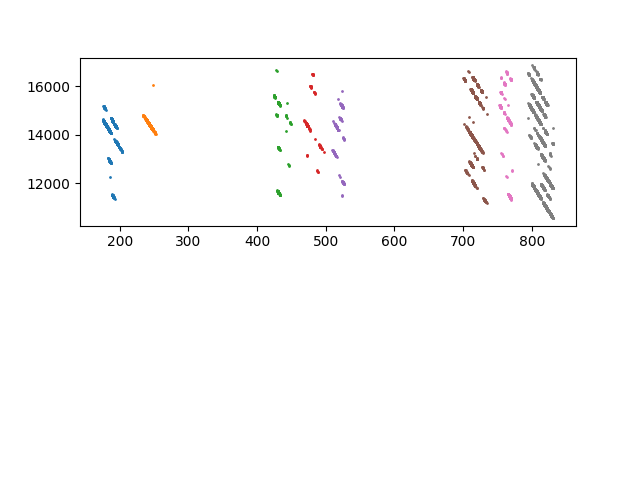

In [4]:
t_sim_list = sio.loadmat(date+'/output_doppler_coarsegs.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
dopp_track_main_dict = sio.loadmat(date+'/doppler_track.mat')['dopp_track_main_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
sat_num = len(dopp_track_dict[0, :])
time_arr, is_middle_arr, dopp_coeff_list = [], [], []
pw_list_0, pw_list_1, pw_list_2 = [], [], []
plt.figure(2)
plt.clf()
plt.subplot(2,1,1)
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    plt.plot(t_repeat, dopp_repeat, '.', label=id_dict[0, sat_idx][0], markersize=2)
plt.show()
plt.ylabel('doppler bin')
# plt.legend(fontsize='x-small', loc='upper right')
plt.subplot(2,1,2)
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)
    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2])**2)
    t = np.arange(t_sat_start, t_sat_end, 0.001)
    dopp = np.polyval(p, t)
    dopp_diff = np.diff(dopp) / np.diff(t)
    t_diff = t[0:-1] + 0.001 / 2
    # find the min value of the derivative
    min_idx = np.argmin(dopp_diff)
    time_arr.append(t_diff[min_idx])
    dopp_coeff_list.append(p)
    pw_list_0.append(np.mean(np.abs(dopp_track[:, 2])**2))
    pw_list_1.append(np.mean(np.abs(dopp_track[:, 3])**2))
    pw_list_2.append(np.mean(np.abs(dopp_track[:, 4])**2))
    is_middle_arr.append(min_idx != 0 and min_idx != len(dopp_diff)-1)
    plt.plot(t_diff, dopp_diff, label=id_dict[0, sat_idx][0], markersize=2)
    plt.scatter(t_diff[min_idx], dopp_diff[min_idx])
plt.ylabel('doppler rate (Hz/s)')
plt.xlabel('time (s)')
is_middle_arr = np.array(is_middle_arr)

Step 5: Blind ID

6Mar2024_04_19
time_arr:  [188.67150050006472, 252.51650050008678, 432.5285004998019, 480.5965004997132, 526.958500499593, 712.3305004997162, 762.8285004997635, 810.602500499615]


/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:179: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Initial number of candidate location clusters: 2865
Possible: 431
Centroid of group  0 : [  35.70800974 -116.87324976]
sats in group: ['STARLINK-2580', 'STARLINK-30606', 'STARLINK-31198', 'STARLINK-1596', 'STARLINK-1231', 'STARLINK-30421', 'STARLINK-5450', 'STARLINK-1605']
Centroid of group  1 : [  37.67922604 -104.87097761]
sats in group: ['STARLINK-1437', 'STARLINK-5782', 'STARLINK-5696', 'STARLINK-30951', 'STARLINK-30039', 'STARLINK-3866', 'STARLINK-3051', 'STARLINK-1899']
Centroid of group  2 : [  37.67922604 -104.87097761]
sats in group: ['STARLINK-1437', 'STARLINK-5782', 'STARLINK-5696', 'STARLINK-30951', 'STARLINK-30521', 'STARLINK-3866', 'STARLINK-3051', 'STARLINK-1899']
Centroid of group  3 : [  39.44403718 -104.18720945]
sats in group: ['STARLINK-30960', 'STARLINK-30956', 'STARLINK-5696', 'STARLINK-1453', 'STARLINK-30039', 'STARLINK-5051', 'STARLINK-3866', 'STARLINK-1899']
Centroid of group  4 : [  39.44403718 -104.18720945]
sats in group: ['STARLINK-30960', 'STARLINK-30956',

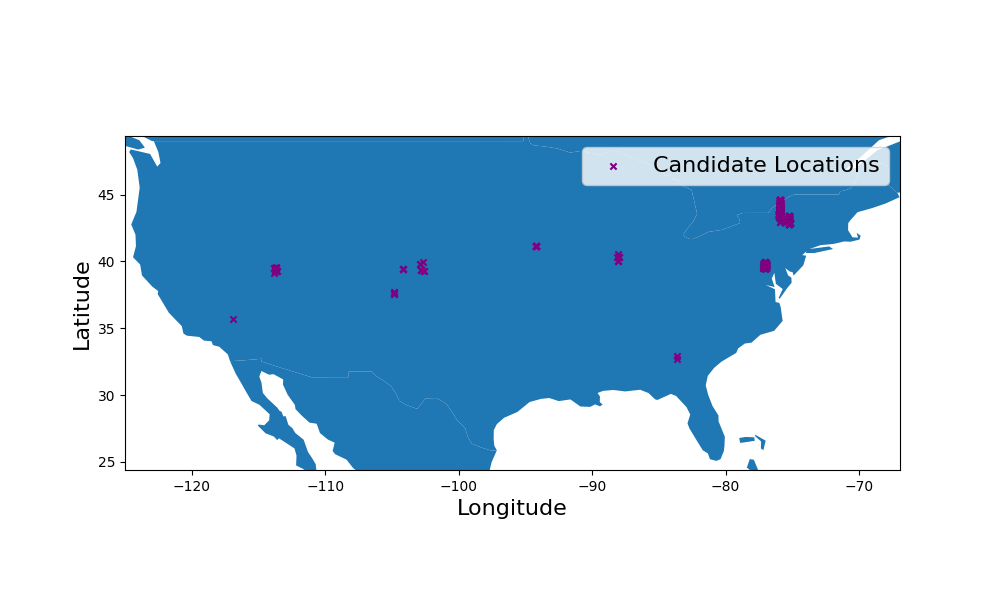

In [5]:
from datetime import datetime
import pytz
# date = os.path.join('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/final', date)
print(date)
start_time_datetime = datetime.fromtimestamp(start_time, tz=pytz.utc)
tle_path = date+'/Starlink.tle'
mat = sio.loadmat(date+'/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
# sort time_arr
# time_arr = sorted(time_arr)
print('time_arr: ', time_arr)
time_arr = np.array(time_arr)
%matplotlib widget
# plt.figure(3)
# plt.clf()
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs, get_candidate_locs_jida
search_radius = 220 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs_jida(start_time_datetime, time_arr, is_middle_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
# ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=30, label='True Location')
ax.legend(fontsize=16)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude', fontsize=16)
ax.set_ylabel('Latitude', fontsize=16)
# ax.set_title('Candidate Ground Station Locations')
plt.savefig(date+'/candidate_gs.pdf')
plt.show()

phase diff to exclude impossible sats, doppler to uniquely determine the id

In [6]:
from sat_id import get_phase_diff_params_allsatsingroups_jida, calc_doppler_blind_id
from utils.helper import get_distkm_latlon_coordinates
from tqdm import tqdm
slope_mes = sio.loadmat(date+'/doppler_track.mat')['slope_mes']
phase_slope = get_phase_diff_params_allsatsingroups_jida(gs_groups, coarse_gs, sat_groups, time_arr+start_time, date+'/Starlink.tle', 0, pitch, roll, d, lam)
phase_slope = np.array(phase_slope)

err = np.array([])
max_phase_err_pergs = [[] for i in range(len(gs_groups))]
refined_candidates = []
remove_candidates = []
for i in (range(len(gs_groups))):
    sat_group_i = sat_groups[i]
    coarse_gs_i = coarse_gs[i]
    phase_slope_i = phase_slope[i]
    err_i = 0
    for j in range(len(sat_group_i)):

        # exclude based on phase slope
        if np.max(np.abs(phase_slope_i[j] - slope_mes[j])) > 0.1:
            err_i = np.inf
            max_phase_err_pergs[i] = np.max(np.abs(phase_slope_i[j] - slope_mes[j]))
            if i in refined_candidates:
                remove_candidates.append(i)
            break
        else:
            max_phase_err_pergs[i] = np.max(np.abs(phase_slope_i[j] - slope_mes[j]))
            refined_candidates.append(i)

        sat_ij = sat_group_i[j]
        dopp_coeff = dopp_coeff_list[j]
        dopp_track = dopp_track_main_dict[0, j]
        t_repeat = dopp_track[:, 0].real
        dopp_repeat = dopp_track[:, 1].real
        t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)
        _, t_dopp_sim, dopp_sim, _, _, _ = calc_doppler_blind_id(sat_ij, coarse_gs_i, t_sat_start+start_time, t_sat_end+start_time, 10)
        t_dopp_sim += t_sat_start
        dopp_mes = np.polyval(dopp_coeff, t_dopp_sim)
        err_i += np.var(dopp_mes-dopp_sim)
    err = np.append(err, err_i)
print('Coarse GS: ', coarse_gs[np.argmin(err)])
coarse_gs_lat, coarse_gs_lon = coarse_gs[np.argmin(err)]
print('Coarse location error in kilometers :', get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon]))
for j in range(len(sat_group_i)):
    print(id_dict[0][j][0] + ': ', sat_groups[np.argmin(err)][j].name == id_dict[0][j][0])
sio.savemat(date+'/blind_id.mat', {'coarse_lat': coarse_gs_lat, 'coarse_lon': coarse_gs_lon})


  0%|          | 0/431 [00:00<?, ?it/s]

100%|██████████| 431/431 [00:15<00:00, 27.32it/s]


Coarse GS:  [ 40.32196238 -88.17100594]
Coarse location error in kilometers : [23.25773921]
STARLINK-3505:  True
STARLINK-5749:  True
STARLINK-3361:  True
STARLINK-4559:  True
STARLINK-3507:  True
STARLINK-5799:  True
STARLINK-3501:  True
STARLINK-4553:  True


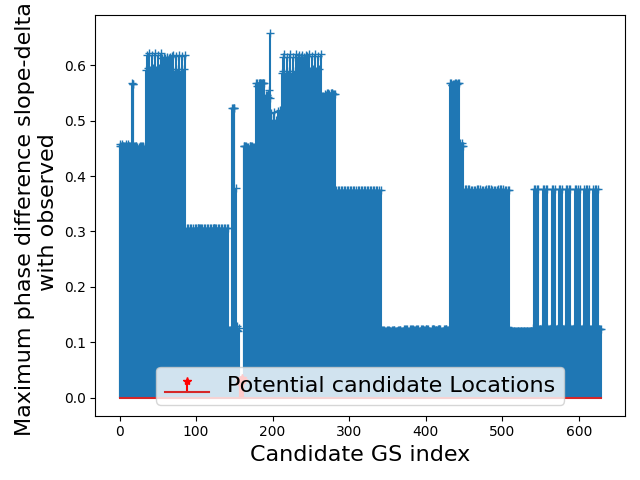

In [10]:
# plot max_phase_err_pergs
# if a number is in remove_candidates, remove it from refined_candidates
refined_candidates = list(set(refined_candidates) - set(remove_candidates))
plt.figure()
plt.stem(range(len(coarse_gs)), max_phase_err_pergs, markerfmt='+')
plt.stem(refined_candidates, np.array(max_phase_err_pergs)[refined_candidates], markerfmt='*', linefmt='r', label='Potential candidate Locations')
plt.xlabel('Candidate GS index', fontsize=16)
plt.ylabel('Maximum phase difference slope-delta \n with observed', fontsize=16)
plt.legend(fontsize=16)
plt.tight_layout()
plt.savefig(date+'/max_phase_err_pergs.pdf')
# plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
# plt.xlabel('Candidate GS index')
# plt.ylabel('Minimum phase difference slope-delta with observed')
# plt.legend()
# plt.show()

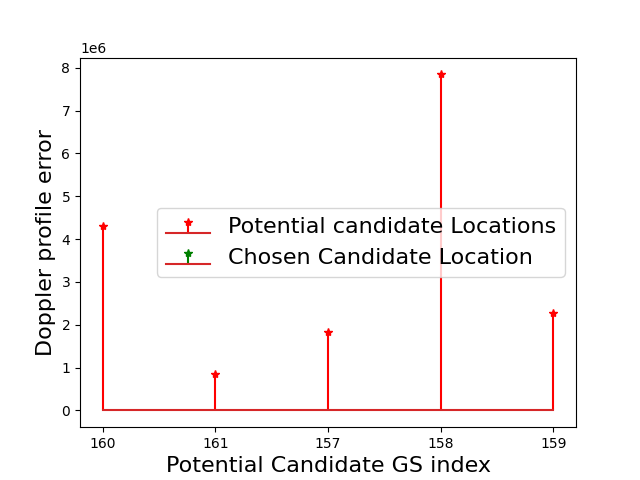

In [11]:
# plot doppler errors now
plt.figure()
x = list(range(len(refined_candidates)))
plt.stem(x, err[refined_candidates], markerfmt='*', linefmt='r', label='Potential candidate Locations')
plt.stem(x[1], err[102], markerfmt='*', linefmt='g', label='Chosen Candidate Location')
# set x ticks
plt.xticks(x, [str(i) for i in refined_candidates])
plt.xlabel('Potential Candidate GS index', fontsize=16)
plt.ylabel('Doppler profile error', fontsize=16)
plt.legend(fontsize=16)
plt.savefig(date+'/doppler_profile_err.pdf')

Step 6: Do localization based on phase diff (this part is moved to `recover_orientation.ipynb`)

/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


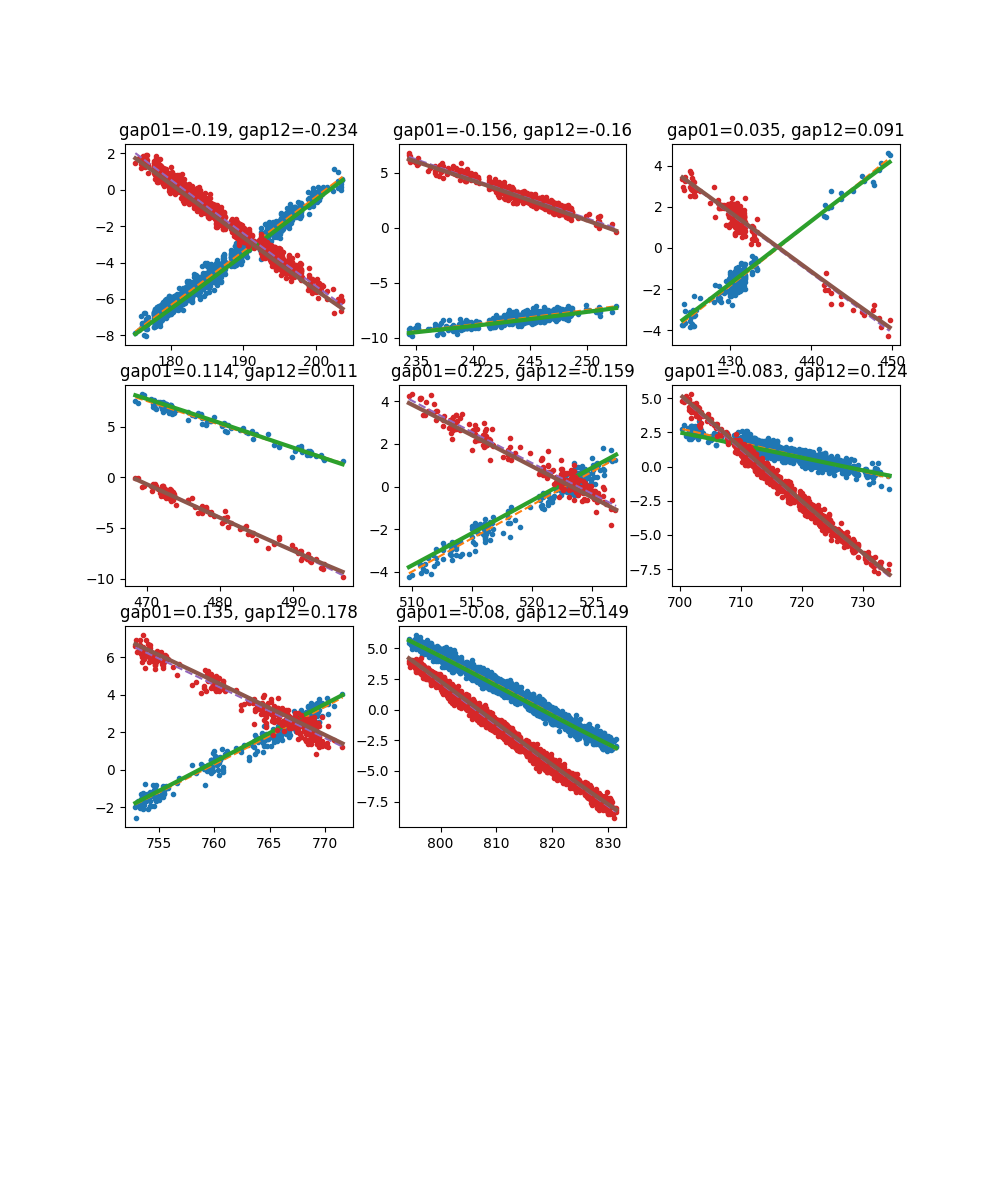

In [7]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 299792458/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# consider orientation - 2: yaw, pitch, roll from imudata
orient = imu.get_attitude()
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
# yaw = 0
R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
R = R_yaw @ R_pitch @ R_roll
loc_0, loc_2 = R @ loc_0, R @ loc_2

# first solve ambiguity
gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
gap_01_coarse_arr, gap_12_coarse_arr = np.array([]), np.array([])
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]

    # gt location
    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    t_sim += t_sat_start
    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)

    # coarse location
    _, az_coarse, el_coarse, range_coarse = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, coarse_gs_lat, coarse_gs_lon)
    az_coarse, el_coarse = np.deg2rad(az_coarse), np.deg2rad(el_coarse)
    
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))
    loc_sat_coarse = np.column_stack((range_coarse * np.cos(el_coarse) * np.sin(az_coarse), range_coarse * np.cos(el_coarse) * np.cos(az_coarse), range_coarse * np.sin(el_coarse)))

    # subtract the ref sig's phase
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]

    # delta phi from measured dopp
    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_

    if date == '12Mar2024_23_17':
        ph_01 = np.array([0.0265, -0.1879, -0.4471, 0.5471-0.4471, 0, -0.0205, -0.2517, 0.0388])
        ph_12 = np.array([0.124, 0.3485, 0.6128, 0.3722, 0, -0.0436, -0.0111, -0.0266])
    elif date == '12Mar2024_23_35':
        ph_01 = np.array([-0.3717, -0.441, -0.0965, 0, -0.0711, 0.093, -0.1751])
        ph_12 = np.array([0.3368, 0.2334, 0.127, 0, 0.0642, -0.3294, 0.0804])
    elif date == '13Mar2024_00_35':
        ph_01 = np.array([0.0434, 0.0658, 0.0982, 0, 0.2041, 0.2524, 0.1915])
        ph_12 = np.array([-0.088, -0.0152, -0.0456, 0, -0.0042, -0.2524, 0.0107])
    elif date == '13Mar2024_00_54':
        ph_01 = np.array([-0.1525, -0.0716, 0.0106, 0, -0.0425, -0.0884])
        ph_12 = np.array([0.0309, -0.0541, -0.0504, 0, 0.0549, -0.0265])
    elif date == '13Mar2024_02_20':
        ph_01 = np.array([0, 0.3867, -0.0084, 0.0772, 0, -0.0086, 0.0027])
        ph_12 = np.array([0, 0.3065, 0.041, 0.0999, 0, -0.2111, -0.1374])
    elif date == '13Mar2024_03_17':
        ph_01 = np.array([.2502, 0.2758, .6393, .3719, .3841, .4612, .4780, .1039, .0887, 0, -.2136, -.0503])
        ph_12 = np.array([.1403, 0.1249, -0.2433, .0103, -.0208, .0372, -0.0372, .0276, -.2927, 0, -.0557, -.0443])
    elif date == '13Mar2024_03_59':
        ph_01 = np.array([0.0024, 0, 0.0162, 0.166])
        ph_12 = np.array([0.0714, 0, -0.0299, -0.3093])
    elif date == '13Mar2024_05_37':
        ph_01 = np.array([-.0296, 0, 0.0765, 0.0456, 0.1201, 0.2308, 0.1292])
        ph_12 = np.array([-0.0597, 0, -0.0097, 0.2716, 0.2427, 0.206, 0.1971])
    elif date == '6Mar2024_03_51':
        ph_01 = np.array([-0.0477, -0.0284, 0, 0.0218, -0.2450, -0.0685, 0.1217, 0.2343])
        ph_12 = np.array([0.0294, 0.011, 0, -0.0223, 0.5448, 0.5625,  0.2096,  0.2841])
    elif date == '20Feb2024_23_19':
        ph_01 = np.array([0.1280, -0.022, -0.0286, 0, -0.131, 0.1443, 0.2638])
        ph_12 = np.array([-0.2556, -0.1533, 0.0147, 0, -0.0135, 0.0125, -0.0446])
    elif date == '5Feb2024_23-58-08':
        ph_01 = np.array([0.0710,-.3306,-.1882,-.0431,0,-.0089,.1341,.0512,-.297,-0.4322])
        ph_12 = np.array([0.0583,.1581,.018,-.0723,0,-.0004,-.0363,.0766,-.0785,-0.0095])
    elif date == '6Mar2024_04_19':
        ph_01 = np.array([-.2288,0,.2107,0,.359,0,.4176,-.0638])
        ph_12 = np.array([-0.2903,0,-0.0231,0,-0.2805,0,0.0312, 0.0673])

    del_phi_repeat_01 += ph_01[sat_idx]
    del_phi_repeat_12 += ph_12[sat_idx]
    
    # delta phi from simulation
    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    range_1_coarse = np.linalg.norm(loc_sat_coarse-loc_1, axis=1)
    range_0_coarse = np.linalg.norm(loc_sat_coarse-loc_0, axis=1)
    range_2_coarse = np.linalg.norm(loc_sat_coarse-loc_2, axis=1)
    del_phi_01_coarse = -(range_0_coarse-range_1_coarse)/lam*2*np.pi
    del_phi_12_coarse = -(range_1_coarse-range_2_coarse)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
    # gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    # gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real
    gap_01_coarse = np.mean(del_phi_01_coarse-np.polyval(coeff_01, t_sim)).real
    gap_12_coarse = np.mean(del_phi_12_coarse-np.polyval(coeff_12, t_sim)).real

    while np.abs(gap_01_coarse-np.mean(gap_01_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01_coarse-np.mean(gap_01_arr))
        gap_01_coarse -= tmp
        del_phi_repeat_01 += tmp
    while np.abs(gap_12_coarse-np.mean(gap_12_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12_coarse-np.mean(gap_12_arr))
        gap_12_coarse -= tmp
        del_phi_repeat_12 += tmp

    gap_01_coarse_arr = np.append(gap_01_coarse_arr, gap_01_coarse)
    gap_12_coarse_arr = np.append(gap_12_coarse_arr, gap_12_coarse)

    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

    # fit the discrete data points with polynomial (second order)
    coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3]))))
    coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4]))))
    del_phi_repeat_01_list.append(del_phi_repeat_01)
    del_phi_repeat_12_list.append(del_phi_repeat_12)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

# plot a large fig
plt.figure(figsize=(10, 12))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(4, 3, sat_idx+1)
    plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt', linewidth=3)
    plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt', linewidth=3)
    
    plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
plt.show()

In [8]:
# do grid search for all satellites
from tqdm import tqdm
x_grid, y_grid = np.linspace(-10e3, 10e3, 200), np.linspace(-10e3, 10e3, 200)
err_min = np.inf
num_sat_for_training = round(sat_num/2)
num_sat_for_testing = sat_num - num_sat_for_training
for x in x_grid:
    for y in y_grid:
        err = 0
        # add some offset to the ground truth location
        loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
        for sat_idx in range(sat_num):
            if sat_idx < num_sat_for_training:
                continue

            t_sim = t_sim_arr[sat_idx]
            mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
            mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
            # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
            # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
            mes_12_diff = np.diff(mes_12)
            mes_01_diff = np.diff(mes_01)
            
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            
            err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y])
loc_aoa_overall_2d = loc_min
loc_aoa_overall_err = np.linalg.norm(loc_aoa_overall_2d)
# print(loc_aoa_overall_2d, loc_aoa_overall_err)

loc_aoa_list = []
for i in tqdm(range(num_sat_for_training, sat_num)):
    err_min = np.inf
    for x in x_grid:
        for y in y_grid:
            err = 0
            # add some offset to the ground truth location
            loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
            for sat_idx in [i]:
                t_sim = t_sim_arr[sat_idx]
                mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
                mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
                # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
                # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
                mes_12_diff = np.diff(mes_12)
                mes_01_diff = np.diff(mes_01)
                
                az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
                loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                            range_gt * np.cos(el_gt) * np.cos(az_gt),
                            range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

                range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
                range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
                range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
                del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
                del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

                if sat_idx < num_sat_for_training:
                    continue
                err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
                # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
            # print(err)
            if err < err_min:
                err_min = err
                loc_min = np.array([x,y])
    # print('sat #'+str(i), loc_min, np.linalg.norm(loc_min))
    loc_aoa_list.append(loc_min)

print(loc_aoa_overall_2d, loc_aoa_overall_err)
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))

100%|██████████| 4/4 [00:08<00:00,  2.24s/it]

[-3969.84924623    50.25125628] 3970.1672794178244
sat #4 [ 1959.79899497 -4472.36180905] 4882.912271555861
sat #5 [-3668.34170854   452.26130653] 3696.115688127295
sat #6 [-4070.35175879 -3869.34673367] 5616.013495858697
sat #7 [-4070.35175879   351.75879397] 4085.522939533235


Doppler based loc

In [14]:
from sat_id import dopp_sim_1_sat
p_list ,tt_sim_list, az_gt_dopp_list, el_gt_dopp_list, range_gt_dopp_list = [], [], [], [], []
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)

    t_sim, dopp_coarse, _, _, _ = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .01, coarse_gs_lat, coarse_gs_lon, alt_gt)
    t_sim += t_sat_start

    _, dopp_gt, az_gt, el_gt, range_gt = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .01, lat_gt, lon_gt, alt_gt)

    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2]))
    freq_offset_ = np.mean(dopp_coarse - np.polyval(p, t_sim))
    p = np.polyfit(t_repeat, dopp_repeat+freq_offset_, 3, w=np.abs(dopp_track[:, 2]))
    
    tt_sim_list.append(t_sim)
    p_list.append(p)
    az_gt_dopp_list.append(np.deg2rad(az_gt))
    el_gt_dopp_list.append(np.deg2rad(el_gt))
    range_gt_dopp_list.append(range_gt)


Optimization based dopp

In [15]:
from scipy.optimize import least_squares
t_step = tt_sim_list[0][1] - tt_sim_list[0][0]
loc_sat_list, dopp_gt_list = [], []
for sat_idx in range(sat_num):
    range_gt, az_gt, el_gt = range_gt_dopp_list[sat_idx], az_gt_dopp_list[sat_idx], el_gt_dopp_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = tt_sim_list[sat_idx]
    # dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2) - np.polyval(p, time_arr[sat_idx]))
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))
    
def residual(params, loc_sat_list, dopp_gt_list, pw_list, fc, t_step, train_num, sat_idx=None):
    c = 299792458
    x, y = params[0], params[1]
    num_sats = len(loc_sat_list)
    loc_rx = np.array([x, y, 0])
    err = 0
    if sat_idx == None:
        for sat_idx in range(train_num, num_sats):
            loc_sat = loc_sat_list[sat_idx]
            dopp_gt = dopp_gt_list[sat_idx]
            the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
            the_range_rate = np.diff(the_range)/t_step
            dopp = -the_range_rate * fc / c + params[sat_idx+2]
            err += np.linalg.norm(dopp-dopp_gt)*pw_list[sat_idx]
    else:
        loc_sat = loc_sat_list[sat_idx]
        dopp_gt = dopp_gt_list[sat_idx]
        the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
        the_range_rate = np.diff(the_range)/t_step
        dopp = -the_range_rate * fc / c + params[sat_idx+2]
        err = np.linalg.norm(dopp-dopp_gt)
    return err
np.random.seed(42)
# overall result
initial_guess = [loc_aoa_overall_2d[0], loc_aoa_overall_2d[1], 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
result = least_squares(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, pw_list_0, fc, t_step, num_sat_for_training))
loc_dopp_overall_2d = result.x[0:2]
loc_dopp_overall_err = np.linalg.norm(loc_dopp_overall_2d)
loc_dopp_list = []
for sat_idx in range(num_sat_for_training, sat_num):
    ii = sat_idx - num_sat_for_training
    initial_guess = [loc_aoa_list[ii][0], loc_aoa_list[ii][1], 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
    result_ii = least_squares(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, pw_list_0, fc, t_step, num_sat_for_training, sat_idx))
    loc_dopp_list.append(result_ii.x[0:2])

Grid search based

In [17]:
from sat_id import dopp_sim_1_sat
p_list ,tt_sim_list, az_gt_dopp_list, el_gt_dopp_list, range_gt_dopp_list = [], [], [], [], []
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)

    t_sim, dopp_gt, az_gt, el_gt, range_gt = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .001, lat_gt, lon_gt, alt_gt)
    t_sim += t_sat_start

    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2]))
    freq_offset_ = np.polyval(p, time_arr[sat_idx])
    p = np.polyfit(t_repeat, dopp_repeat-freq_offset_, 3, w=np.abs(dopp_track[:, 2]))
    
    tt_sim_list.append(t_sim)
    p_list.append(p)
    az_gt_dopp_list.append(np.deg2rad(az_gt))
    el_gt_dopp_list.append(np.deg2rad(el_gt))
    range_gt_dopp_list.append(range_gt)


100%|██████████| 8/8 [00:02<00:00,  3.34it/s]


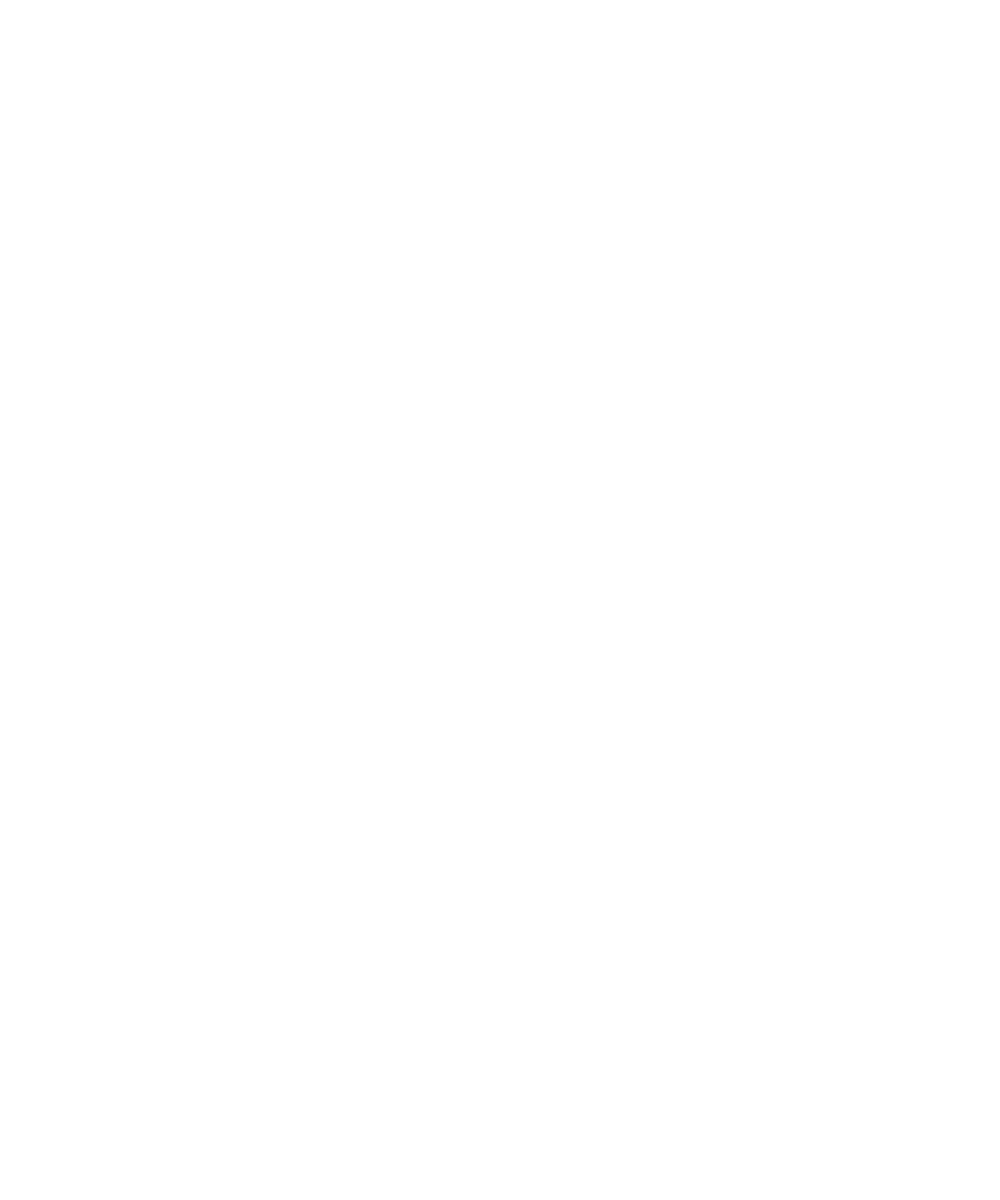

In [18]:
t_step = tt_sim_list[0][1] - tt_sim_list[0][0]
loc_sat_list, dopp_gt_list = [], []
plt.clf()
for sat_idx in range(sat_num):
    range_gt, az_gt, el_gt = range_gt_dopp_list[sat_idx], az_gt_dopp_list[sat_idx], el_gt_dopp_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = tt_sim_list[sat_idx]
    # dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2) - np.polyval(p, time_arr[sat_idx]))
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))
    # plt.plot(t_sim[0:-1]+(t_step)/2, np.polyval(p, t_sim[0:-1]+(t_step)/2), label='fit')
loc_dopp_grid_list = []
x_grid, y_grid = np.linspace(-15e3, 15e3, 30), np.linspace(-15e3, 15e3, 30)
for sat_idx in tqdm(range(sat_num)):
    err_min = np.inf
    if not is_middle_arr[sat_idx]:
        continue
    for x in x_grid:
        for y in y_grid:
            err = 0
            # add some offset to the ground truth location
            loc_sat = loc_sat_list[sat_idx]
            dopp_gt = dopp_gt_list[sat_idx]
            the_range = np.linalg.norm(loc_sat-np.array([x,y,0]), axis=1)
            the_range_rate = np.diff(the_range)/t_step
            dopp = -the_range_rate * fc / 299792458
            t_sim = tt_sim_list[sat_idx]
            # plt.plot(t_sim[0:-1]+(t_step)/2, dopp)
            # plt.plot(t_sim[0:-1]+(t_step)/2, dopp_gt, '--')
            err = np.linalg.norm(dopp-dopp_gt)
            if err < err_min:
                err_min = err
                loc_min_dopp_grid = np.array([x,y])
    loc_dopp_grid_list.append(loc_min_dopp_grid)
plt.show()
# print(loc_aoa_overall_2d, loc_aoa_overall_err)
# for i in range(num_sat_for_testing):
    # print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))

In [19]:
# print all results
print('capture '+ date)
print('1. ground truth lat, lon in degrees')
print(lat_gt, lon_gt)
print('2. coarse lat, lon in degrees')
print(coarse_gs_lat, coarse_gs_lon)
print('3. coarse location error in kilometers')
print(get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon])[0])
print('4. total satellite number, number of satellites for training')
print(sat_num, num_sat_for_training)
print('5. phase based overall result: 2d in meters, error in meters')
print(loc_aoa_overall_2d[0], loc_aoa_overall_2d[1], loc_aoa_overall_err)
print('6. doppler based overall result: 2d in meters, error in meters')
print(loc_dopp_overall_2d[0], loc_dopp_overall_2d[1], loc_dopp_overall_err)
print('7. avearge overall loc result')
print((loc_aoa_overall_2d[0]+loc_dopp_overall_2d[0])/2, (loc_aoa_overall_2d[1]+loc_dopp_overall_2d[1])/2, np.sqrt(((loc_aoa_overall_2d[0]+loc_dopp_overall_2d[0])/2)**2+((loc_aoa_overall_2d[1]+loc_dopp_overall_2d[1])/2)**2))
print('8. individual satellite results - phase based')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i][0], loc_aoa_list[i][1], np.linalg.norm(loc_aoa_list[i]))
print('9. individual satellite results - doppler based')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_dopp_list[i][0], loc_dopp_list[i][1], np.linalg.norm(loc_dopp_list[i]))
print('10. individual satellite results - doppler + phase')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), (loc_aoa_list[i][0]+loc_dopp_list[i][0])/2, (loc_aoa_list[i][1]+loc_dopp_list[i][1])/2, np.linalg.norm((loc_aoa_list[i]+loc_dopp_list[i])/2))

capture 6Mar2024_04_19
1. ground truth lat, lon in degrees
40.1171203863895 -88.22639025706695
2. coarse lat, lon in degrees
40.40199632263845 -88.12218012070711
3. coarse location error in kilometers
32.887868149111114
4. total satellite number, number of satellites for training
8 4
5. phase based overall result: 2d in meters, error in meters
-1859.29648241206 150.75376884422076 1865.3981098764405
6. doppler based overall result: 2d in meters, error in meters
1460.6038298980316 7145.005206242209 7292.767852135503
7. avearge overall loc result
-199.3463262570142 3647.879487543215 3653.322284364017
8. individual satellite results - phase based
sat #4 -2261.306532663316 1457.286432160805 2690.2027767485774
sat #5 -2261.306532663316 753.7688442211056 2383.6263770113405
sat #6 -2864.3216080402008 3668.3417085427136 4654.145374278727
sat #7 -1356.7839195979886 -351.75879396984965 1401.6407719579238
9. individual satellite results - doppler based
sat #4 -3652.0051002256027 2644.2507380247457